In [ ]:
import urllib.request
import tarfile
import os
from pathlib import Path

# Đường dẫn thư mục đích
DATA_DIR = Path("../data/raw")
DATA_DIR.mkdir(parents=True, exist_ok=True)

# Danh sách các file cần tải
urls = {
    "102flowers.tgz": "https://www.robots.ox.ac.uk/~vgg/data/flowers/102/102flowers.tgz",
    "imagelabels.mat": "https://www.robots.ox.ac.uk/~vgg/data/flowers/102/imagelabels.mat",
    "setid.mat": "https://www.robots.ox.ac.uk/~vgg/data/flowers/102/setid.mat"
}

# 1. Tải dữ liệu
for filename, url in urls.items():
    filepath = DATA_DIR / filename
    if not filepath.exists():
        print(f"⏳ Đang tải {filename} (có thể mất vài phút)...")
        urllib.request.urlretrieve(url, filepath)
        print(f"✅ Đã tải xong {filename}")
    else:
        print(f"ℹ️ {filename} đã tồn tại, bỏ qua tải.")

# 2. Giải nén ảnh
tar_path = DATA_DIR / "102flowers.tgz"
if tar_path.exists():
    print("⏳ Đang giải nén 102flowers.tgz...")
    with tarfile.open(tar_path, "r:gz") as tar:
        tar.extractall(path=DATA_DIR)
    print("✅ Giải nén hoàn tất!")
else:
    print("❌ Không tìm thấy file 102flowers.tgz để giải nén.")

# 3. Kiểm tra lại
if (DATA_DIR / "imagelabels.mat").exists() and (DATA_DIR / "jpg").exists():
    print("\n🎉 TUYỆT VỜI! Dữ liệu đã sẵn sàng trong thư mục data/raw/")
else:
    print("\n❌ Vẫn còn thiếu file. Hãy kiểm tra lại kết nối mạng.")

⏳ Đang tải 102flowers.tgz (có thể mất vài phút)...
✅ Đã tải xong 102flowers.tgz
⏳ Đang tải imagelabels.mat (có thể mất vài phút)...
✅ Đã tải xong imagelabels.mat
⏳ Đang tải setid.mat (có thể mất vài phút)...
✅ Đã tải xong setid.mat
⏳ Đang giải nén 102flowers.tgz...
✅ Giải nén hoàn tất!

🎉 TUYỆT VỜI! Dữ liệu đã sẵn sàng trong thư mục data/raw/


In [4]:
# Đọc file nhãn và phân chia tập
labels = scipy.io.loadmat(DATA_DIR / "imagelabels.mat")["labels"][0]
setid = scipy.io.loadmat(DATA_DIR / "setid.mat")

# Trừ 1 để chuyển từ index của MATLAB (1-based) sang Python (0-based)
train_ids = setid["trnid"][0] - 1
val_ids   = setid["valid"][0] - 1
test_ids  = setid["tstid"][0] - 1

print(f"Tổng số ảnh: {len(labels)}")
print(f"Số lượng lớp (loài hoa): {len(np.unique(labels))}")
print(f"- Tập Train: {len(train_ids)} ảnh")
print(f"- Tập Validation: {len(val_ids)} ảnh")
print(f"- Tập Test: {len(test_ids)} ảnh")

Tổng số ảnh: 8189
Số lượng lớp (loài hoa): 102
- Tập Train: 1020 ảnh
- Tập Validation: 1020 ảnh
- Tập Test: 6149 ảnh


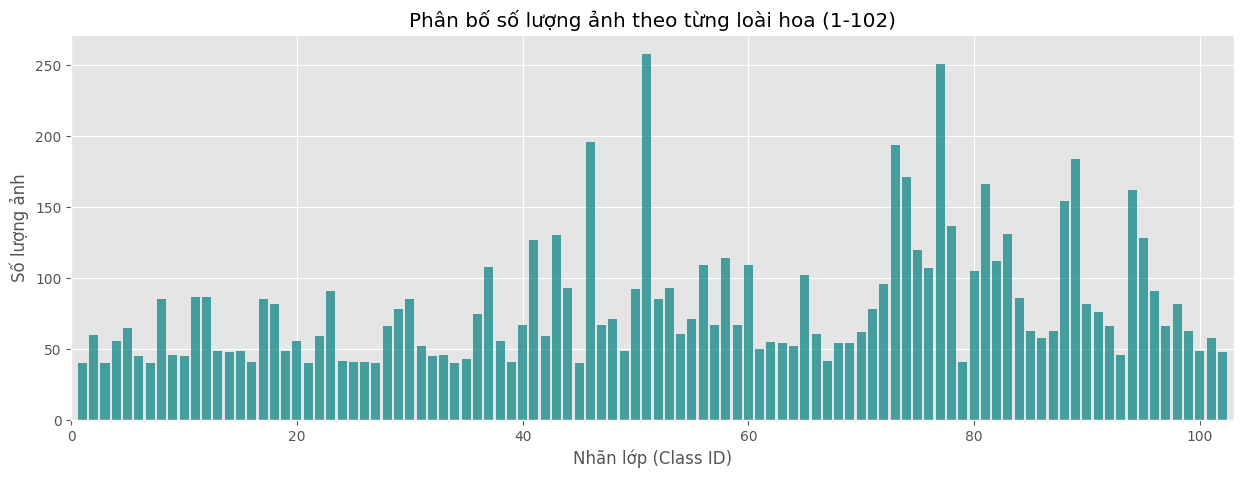

Số ảnh ít nhất trong 1 lớp: 40
Số ảnh nhiều nhất trong 1 lớp: 258


In [5]:
# Đếm số lượng ảnh của từng lớp
class_counts = pd.Series(labels).value_counts().sort_index()

plt.figure(figsize=(15, 5))
plt.bar(class_counts.index, class_counts.values, color='teal', alpha=0.7)
plt.title("Phân bố số lượng ảnh theo từng loài hoa (1-102)")
plt.xlabel("Nhãn lớp (Class ID)")
plt.ylabel("Số lượng ảnh")
plt.xlim(0, 103)
plt.show()

print(f"Số ảnh ít nhất trong 1 lớp: {class_counts.min()}")
print(f"Số ảnh nhiều nhất trong 1 lớp: {class_counts.max()}")

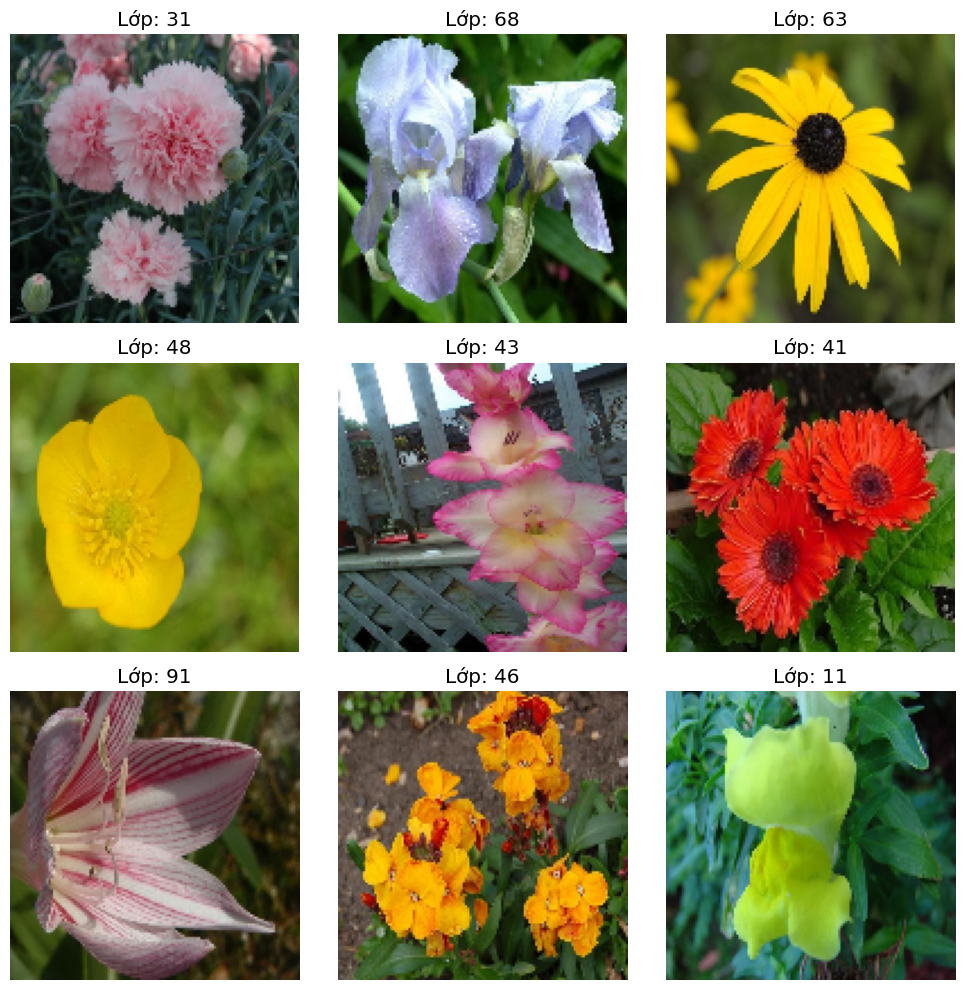

In [6]:
def load_image(img_id, size=(128, 128)):
    """Đọc 1 ảnh từ ID (ID bắt đầu từ 0 trong Python)"""
    path = DATA_DIR / "jpg" / f"image_{img_id+1:05d}.jpg" # +1 vì tên file bắt đầu từ 1
    img = cv2.imread(str(path))
    if img is None:
        return np.zeros((size[0], size[1], 3), dtype=np.uint8)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB) # Chuyển BGR sang RGB để hiển thị đúng màu
    img = cv2.resize(img, size)
    return img

# Lấy ngẫu nhiên ảnh từ 9 lớp khác nhau để xem
np.random.seed(42)
random_classes = np.random.choice(np.unique(labels), 9, replace=False)

fig, axes = plt.subplots(3, 3, figsize=(10, 10))
for ax, cls in zip(axes.flatten(), random_classes):
    # Tìm 1 ảnh thuộc lớp này
    idx = np.where(labels == cls)[0][0]
    img = load_image(idx)
    
    ax.imshow(img)
    ax.set_title(f"Lớp: {cls}")
    ax.axis('off')

plt.tight_layout()
plt.show()